In [3]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import funcs
import astropy.io.fits as fits
from astropy.table import Table
from astropy.cosmology import WMAP9 as cosmo
import h5py

path_simba = "../simba_rlf_data/df_simba.pkl"
df_simba = pd.read_pickle(path_simba)

path_manga = "../simba_rlf_data/df_manga.pkl"
df_manga = pd.read_pickle(path_manga)

path_nt = "../simba_rlf_data/df_nt.pkl"
df_nt = pd.read_pickle(path_nt)

In [4]:
print(df_simba.columns)
print(df_nt.columns)

Index(['log_sfr', 'bhmdot', 'log_bhm', 'fedd', 'log_ssfr', 'log_mass',
       'bhm_nt', 'bhm_dot_50Myr', 'log_lsf_thermal', 'log_lsf_non_thermal',
       'log_lsf_nt', 'log_lagn_nt', 'log_lr_total_nt'],
      dtype='object')
Index(['BHAR_50MYR', 'BHAR_BONDI_50MYR', 'BH_Mass', 'ID', 'Jgas_x', 'Jgas_y',
       'Jgas_z', 'Jstar_x', 'Jstar_y', 'Jstar_z', 'Mass', 'Mass_AlphaDisk',
       'Mdot', 'Mdot_alphadisk', 'Mdot_bondi', 'Mgas', 'MgasBulge', 'Mhot',
       'Mstar', 'MstarBulge', 'R0', 'RG', 'Sfr', 'a', 'dt', 'e', 'logP_14',
       'p_x', 'p_y', 'p_z', 'rho', 'v_x', 'v_y', 'v_z'],
      dtype='object')


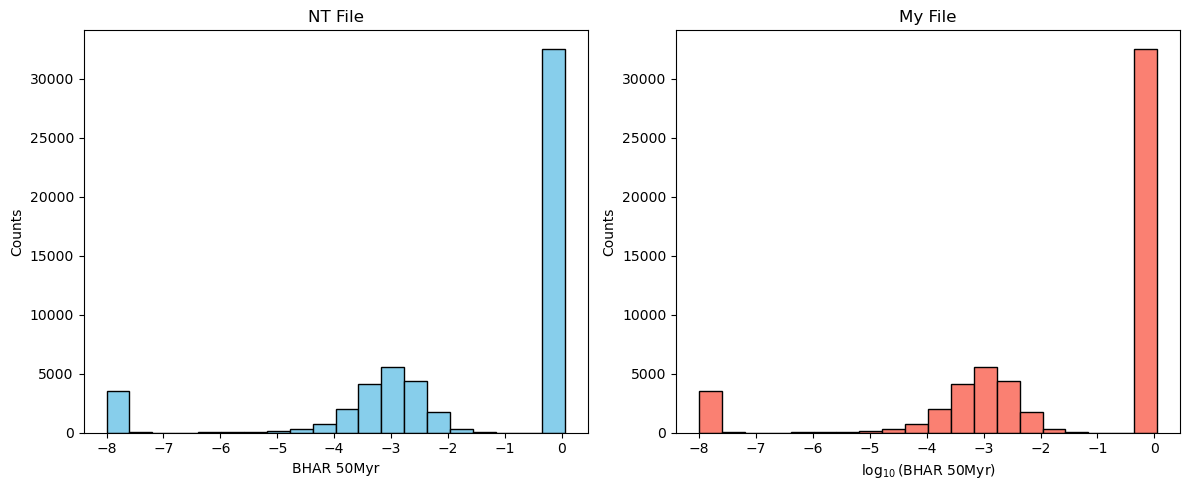

In [16]:
#Create a figure with 1 row and 2 columns of subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- Left Subplot: NT File ---
# Dropping NaNs ensures matplotlib calculates the histogram bins cleanly
ax1.hist(df_nt['BHAR_50MYR'].dropna(), bins=20, color='skyblue', edgecolor='black')
ax1.set_title("NT File")
ax1.set_xlabel('BHAR 50Myr')
ax1.set_ylabel('Counts')

# --- Right Subplot: My File ---
# Compute log10 and drop any resulting NaNs/Infs from zero or negative entries
log_bhar_simba = np.log10(df_simba['bhm_dot_50Myr'])
log_bhar_simba = log_bhar_simba[np.isfinite(log_bhar_simba)]

ax2.hist(log_bhar_simba, bins=20, color='salmon', edgecolor='black')
ax2.set_title("My File")
ax2.set_xlabel("$\log_{10}$(BHAR 50Myr)")  # Formatted with LaTeX for visual clarity
ax2.set_ylabel('Counts')

# Adjust layout automatically so titles and labels don't overlap
plt.tight_layout()
plt.show()

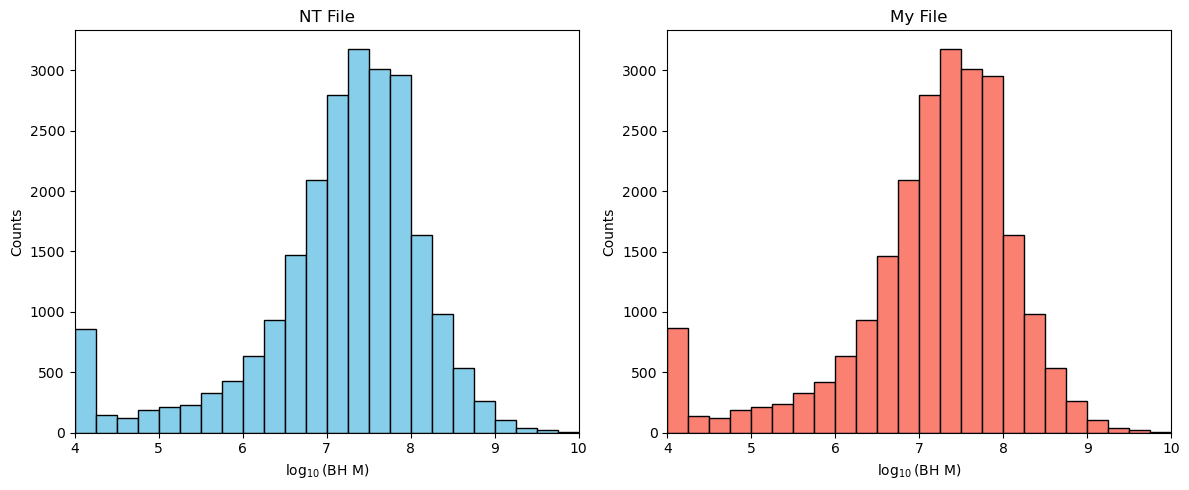

In [17]:
# Create a figure with 1 row and 2 columns of subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Define uniform bin edges between your x-limits for easy comparison
shared_bins = np.linspace(4, 10, 25)

# --- Left Subplot: NT File ---
# Filter out values <= 0 before applying log10
bhm_nt = df_nt['BH_Mass']
log_bhm_nt = np.log10(bhm_nt[bhm_nt > 0])

ax1.hist(log_bhm_nt, bins=shared_bins, color='skyblue', edgecolor='black')
ax1.set_title("NT File")
ax1.set_xlabel('$\log_{10}$(BH M)')
ax1.set_ylabel('Counts')
ax1.set_xlim(4, 10)

# --- Right Subplot: My File ---
# Filter out -inf values
log_bhm_simba = df_simba['log_bhm']
log_bhm_simba_filtered = log_bhm_simba[log_bhm_simba > -np.inf]

ax2.hist(log_bhm_simba_filtered, bins=shared_bins, color='salmon', edgecolor='black')
ax2.set_title("My File")
ax2.set_xlabel('$\log_{10}$(BH M)')
ax2.set_ylabel('Counts')
ax2.set_xlim(4, 10)

# Adjust spacing between plots automatically
plt.tight_layout()
plt.show()

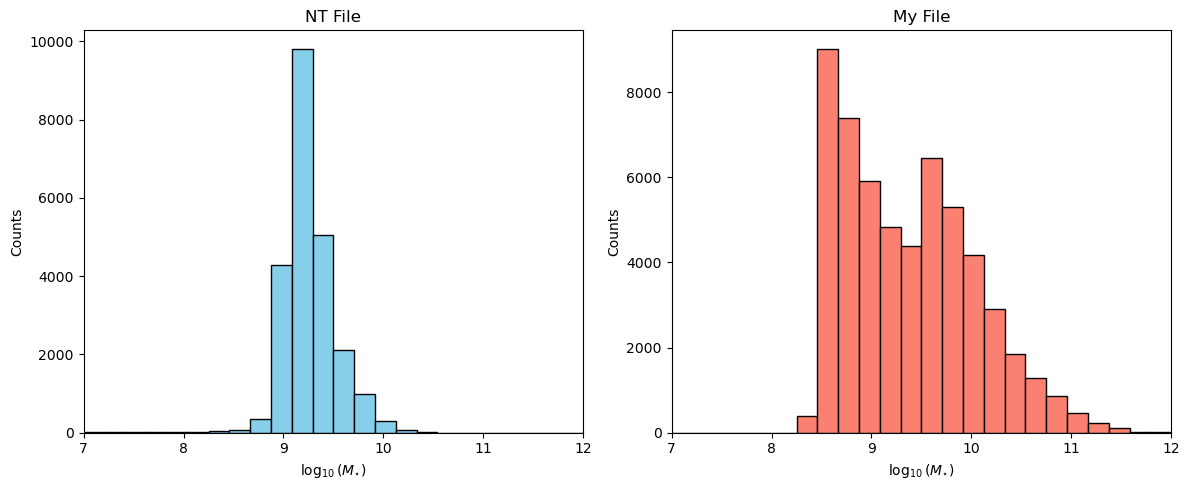

In [18]:
# Create a figure with 1 row and 2 columns of subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Define uniform bin edges between your x-limits for easy comparison
shared_bins = np.linspace(7, 12, 25)

# --- Left Subplot: NT File ---
# Filter Mstar based on rows where BH_Mass > 0, then apply log10
mstar_nt = df_nt['Mstar'][df_nt['BH_Mass'] > 0]
log_mstar_nt = np.log10(mstar_nt)

ax1.hist(log_mstar_nt, bins=shared_bins, color='skyblue', edgecolor='black')
ax1.set_title("NT File")
ax1.set_xlabel('$\log_{10}(M_{\star})$')
ax1.set_ylabel('Counts')
ax1.set_xlim(7, 12)

# --- Right Subplot: My File ---
# Filter out -inf values from log_mass
log_mass_simba = df_simba['log_mass']
log_mass_simba_filtered = log_mass_simba[log_mass_simba > -np.inf]

ax2.hist(log_mass_simba_filtered, bins=shared_bins, color='salmon', edgecolor='black')
ax2.set_title("My File")
ax2.set_xlabel('$\log_{10}(M_{\star})$')
ax2.set_ylabel('Counts')
ax2.set_xlim(7, 12)

# Adjust spacing between plots automatically
plt.tight_layout()
plt.show()

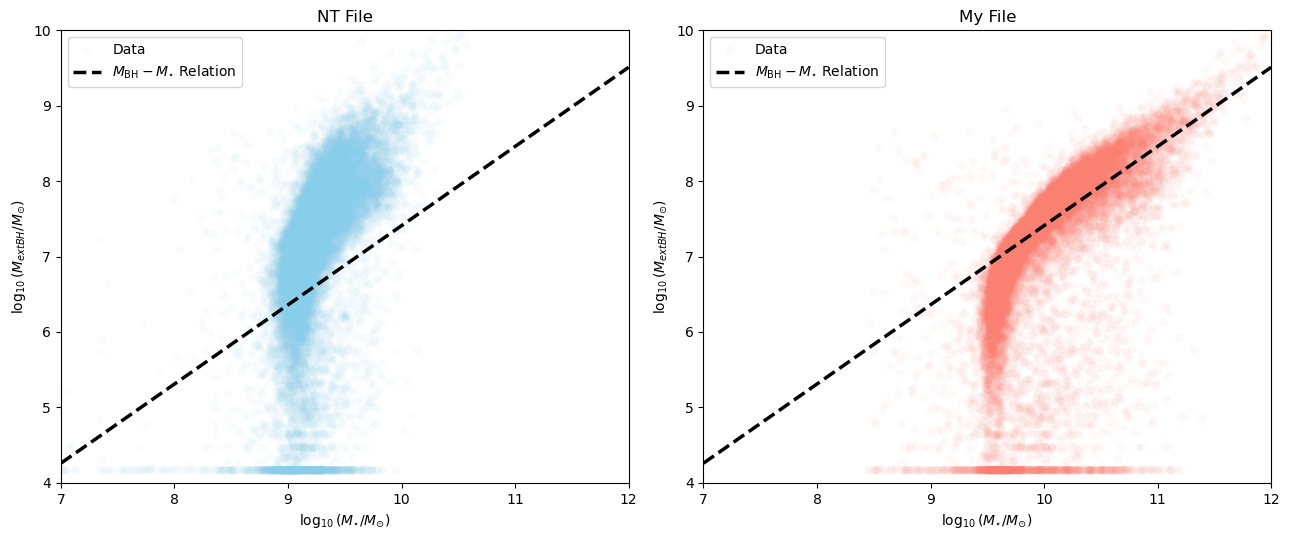

In [22]:
# Create a figure with 1 row and 2 columns of subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

# --- Define the M_bh - M_star Scaling Relation Line ---
# We generate a grid of log(M_star) values to plot the line across
x_relation = np.linspace(7, 12, 100)

# McConnell & Ma (2013) relation: log10(Mbh) = 8.46 + 1.05 * log10(Mstar / 10^11)
y_relation = 8.46 + 1.05 * (x_relation - 11)

# Note: If you want to use the Reines & Volonteri (2015) relation for total mass instead, 
# you can comment out the line above and uncomment the line below:
# y_relation = 7.45 + 1.05 * (x_relation - 11)


# --- Left Subplot: NT File ---
valid_nt = (df_nt['Mstar'] > 0) & (df_nt['BH_Mass'] > 0)
log_mstar_nt = np.log10(df_nt['Mstar'][valid_nt])
log_bhm_nt = np.log10(df_nt['BH_Mass'][valid_nt])

# Scatter points
ax1.scatter(log_mstar_nt, log_bhm_nt, alpha=0.05, color='skyblue', edgecolor='none', label='Data')
# Relation line
ax1.plot(x_relation, y_relation, color='black', linestyle='--', linewidth=2.5, label='$M_{\\text{BH}} - M_{\\star}$ Relation')

ax1.set_title("NT File")
ax1.set_xlabel('$\log_{10}(M_{\star} / M_{\odot})$')
ax1.set_ylabel('$\log_{10}(M_{\text{BH}} / M_{\odot})$')
ax1.set_xlim(7, 12)
ax1.set_ylim(4, 10)
ax1.legend(loc='upper left')


# --- Right Subplot: My File ---
valid_simba = (df_simba['log_mass'] > -np.inf) & (df_simba['log_bhm'] > -np.inf)
log_mass_simba = df_simba['log_mass'][valid_simba]
log_bhm_simba = df_simba['log_bhm'][valid_simba]

# Scatter points
ax2.scatter(log_mass_simba, log_bhm_simba, alpha=0.05, color='salmon', edgecolor='none', label='Data')
# Relation line
ax2.plot(x_relation, y_relation, color='black', linestyle='--', linewidth=2.5, label='$M_{\\text{BH}} - M_{\\star}$ Relation')

ax2.set_title("My File")
ax2.set_xlabel('$\log_{10}(M_{\star} / M_{\odot})$')
ax2.set_ylabel('$\log_{10}(M_{\text{BH}} / M_{\odot})$')
ax2.set_xlim(7, 12)
ax2.set_ylim(4, 10)
ax2.legend(loc='upper left')


# Adjust spacing automatically so labels and legends don't overlap
plt.tight_layout()
plt.show()

In [23]:
def plot_rlf(df, filename, ax):



    if filename == "NT":

        radio_colname = "logP_14"

        unit_conversion = 0

        n_snapshots = 1

        volume = n_snapshots*(100)**3


    elif filename == "my_file":

        radio_colname = "log_lr_total_nt"

        unit_conversion = -16.15

        n_snapshots = 1

        volume = n_snapshots*(100)**3



    else:

        radio_colname = "log_lr_total_nt"

        unit_conversion = -16.15

        n_snapshots = 9

        volume = n_snapshots*(100)**3



    log_lrs = df[radio_colname] + unit_conversion
    log_lrs = log_lrs[(log_lrs > 19) & (log_lrs < 26)]

    bins = np.linspace(19,26,15)
    range = 25-19
    bin_width = range/15

    counts, bins = np.histogram(log_lrs, bins = bins)
    bin_centers = (bins[:-1] + bins[1:])/2
    counts_per_dex = counts/bin_width
    log_rlf = np.log10(counts_per_dex/volume)

    ax.plot(bin_centers, log_rlf, c = 'k',linewidth = 5, label = 'All')



    radio_colname_sf = "log_lsf_nt"
    radio_colname_agn = "log_lagn_nt"


    log_lrs_sf = df[radio_colname_sf] + unit_conversion
    log_lrs_sf = log_lrs_sf[(log_lrs_sf > 19) & (log_lrs_sf < 26)]
    counts_sf, bins = np.histogram(log_lrs_sf, bins = bins)
    counts_sf_per_dex = counts_sf/bin_width
    log_rlf_sf = np.log10(counts_sf_per_dex/volume)



    log_lrs_agn = df[radio_colname_agn] + unit_conversion

    log_lrs_agn = log_lrs_agn[(log_lrs_agn > 19) & (log_lrs_agn < 26)]

    counts_agn, bins = np.histogram(log_lrs_agn, bins = bins)

    counts_agn_per_dex = counts_agn/bin_width

    log_rlf_agn = np.log10(counts_agn_per_dex/volume)



    ax.plot(bin_centers, log_rlf_sf, linestyle = 'dashed', c = 'b', linewidth = 5, label = 'SF')
    ax.plot(bin_centers, log_rlf_agn, linestyle = 'dashed', c = 'r', linewidth = 5, label = 'AGN')


    plt.legend()

/tmp/ipykernel_1789190/3980460682.py:50: RuntimeWarning: divide by zero encountered in log10
  log_rlf = np.log10(counts_per_dex/volume)
/tmp/ipykernel_1789190/3980460682.py:64: RuntimeWarning: divide by zero encountered in log10
  log_rlf_sf = np.log10(counts_sf_per_dex/volume)
/tmp/ipykernel_1789190/3980460682.py:76: RuntimeWarning: divide by zero encountered in log10
  log_rlf_agn = np.log10(counts_agn_per_dex/volume)


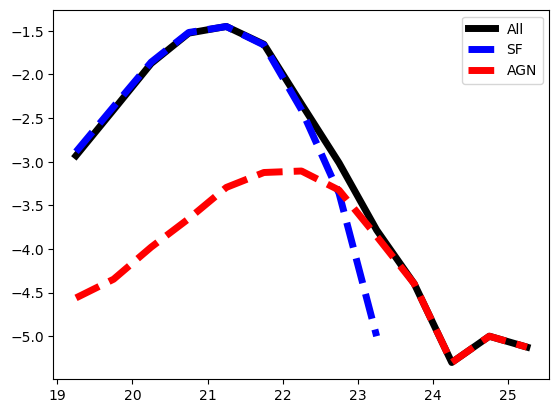

In [24]:
fig, ax = plt.subplots(1)

plot_rlf(df_simba, "my_file", ax)
plt.show()